# Projet : Reconnaissance des émotions faciales dans les vidéos RAVDESS

- **Master :** Web Intelligence et Sciences des Données (WISD), FSDM, USMBA Fès
- **Module :** Exploration intelligente des images par Deep Learning
- **Professeur :** Pr. Abdelouahed Sabri
- **Réalisé par :** Yahia Khroufi
- **Année universitaire :** 2026–2027

---

### Objectif
Reconnaître l'émotion d'une vidéo (8 classes) à partir de la **suite de ses frames**.

### Travail demandé
1. Ajouter une **méthode de sélection de frames** pour éviter la redondance.
2. Extraire les caractéristiques de chaque frame avec un **CNN** (VGG16 pré-entraîné).
3. **Deuxième tâche :** extraire des caractéristiques couleur par **moments statistiques** (moyenne, écart-type).
4. Comparer **RNN, LSTM, GRU et Transformer**.
5. Donner les métriques du CNN (extraction de features) et des modèles séquentiels.

### Plan du notebook
1. Importation des bibliothèques
2. Accès aux données (Google Drive)
3. Chargement et exploration de la base
4. Détection et recadrage du visage
5. Sélection des frames
6. Extraction des caractéristiques (VGG16 + moments couleur)
7. Préparation des séquences et protocole d'évaluation
8. Métriques du CNN extracteur
9. Modèles séquentiels : RNN, LSTM, GRU, Transformer
10. Comparaison des résultats
11. Sauvegarde des résultats

## 1. Importation des bibliothèques

In [14]:
import os, glob, time, json, random, pickle, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

warnings.filterwarnings('ignore')
print('TensorFlow :', tf.__version__)
print('GPU :', tf.config.list_physical_devices('GPU'))

TensorFlow : 2.21.0
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [15]:
# Graine aléatoire pour avoir des résultats reproductibles
SEED = 42

def fixer_graine(s=SEED):
    random.seed(s)
    np.random.seed(s)
    tf.random.set_seed(s)

fixer_graine()

# Paramètres du projet
IMG = 128        # taille des images (comme dans l'article de référence)
T = 16           # nombre de frames gardées par vidéo
N_FOLDS = 5      # validation croisée à 5 plis

EMOTIONS = ['neutre', 'calme', 'joie', 'tristesse', 'colere', 'peur', 'degout', 'surprise']

## 2. Accès aux données (Google Drive)
Le dossier partagé par le professeur doit être ajouté dans « Mon Drive » (clic droit > Organiser > Ajouter un raccourci).

In [16]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [17]:
# Recherche du dossier Actor_01 dans Mon Drive
chemins_possibles = (glob.glob('/content/drive/MyDrive/RAVDESS_Video_Speech/*/Actor_01') +
                     glob.glob('/content/drive/MyDrive/*/RAVDESS_Video_Speech/*/Actor_01') +
                     glob.glob('/content/drive/MyDrive/*/Actor_01') +
                     glob.glob('/content/drive/MyDrive/Actor_01'))
assert len(chemins_possibles) > 0, "Dossier introuvable : ajouter le raccourci RAVDESS dans Mon Drive."

DATA_DIR = chemins_possibles[0]
OUT_DIR = '/content/drive/MyDrive/RAVDESS_Projet_Resultats'   # dossier où on sauvegarde les résultats
os.makedirs(OUT_DIR, exist_ok=True)

print('Données   :', DATA_DIR)
print('Résultats :', OUT_DIR)

Données   : /content/drive/MyDrive/Video_Speech_Actor_01 (1)/Actor_01
Résultats : /content/drive/MyDrive/RAVDESS_Projet_Resultats


## 3. Chargement et exploration de la base

D'après le fichier *Dataset Description.txt*, le nom de chaque vidéo contient 7 nombres :
`Modalité - Canal - Émotion - Intensité - Phrase - Répétition - Acteur`

* Modalité : 01 = audio + vidéo, 02 = vidéo seule
* **Émotion (3e nombre) = l'étiquette** : 01 neutre, 02 calme, 03 joie, 04 tristesse, 05 colère, 06 peur, 07 dégoût, 08 surprise

In [18]:
def lire_nom(chemin):
    # exemple : 02-01-06-01-02-01-01.mp4
    p = os.path.basename(chemin)[:-4].split('-')
    return {'path': chemin, 'file': os.path.basename(chemin),
            'modalite': int(p[0]), 'canal': int(p[1]), 'emotion': int(p[2]),
            'intensite': int(p[3]), 'phrase': int(p[4]), 'repetition': int(p[5]), 'acteur': int(p[6])}

fichiers = sorted(glob.glob(os.path.join(DATA_DIR, '*.mp4')))
df_tout = pd.DataFrame([lire_nom(f) for f in fichiers])

print('Nombre total de vidéos :', len(df_tout))
print(df_tout['modalite'].value_counts().rename({1: 'audio+video (01)', 2: 'video seule (02)'}))
df_tout.head()

Nombre total de vidéos : 120
modalite
audio+video (01)    60
video seule (02)    60
Name: count, dtype: int64


,path,file,modalite,canal,emotion,intensite,phrase,repetition,acteur
0,/content/drive/MyDrive/Video_Speech_Actor_01 (...,01-01-01-01-01-01-01.mp4,1,1,1,1,1,1,1
1,/content/drive/MyDrive/Video_Speech_Actor_01 (...,01-01-01-01-01-02-01.mp4,1,1,1,1,1,2,1
2,/content/drive/MyDrive/Video_Speech_Actor_01 (...,01-01-01-01-02-01-01.mp4,1,1,1,1,2,1,1
3,/content/drive/MyDrive/Video_Speech_Actor_01 (...,01-01-01-01-02-02-01.mp4,1,1,1,1,2,2,1
4,/content/drive/MyDrive/Video_Speech_Actor_01 (...,01-01-02-01-01-01-01.mp4,1,1,2,1,1,1,1


**Remarque importante :** les fichiers `01-...` et `02-...` sont le **même enregistrement** (la version 02 est la version 01 sans le son).
Si on garde les deux, une même vidéo peut se retrouver dans l'apprentissage et dans le test, ce qui fausse les résultats.
On garde donc **seulement la modalité 02 (vidéo seule)**.

In [19]:
# Lecture de toutes les frames d'une vidéo (réduites à 640 px de large pour aller plus vite)
def lire_frames(chemin, largeur=640):
    cap = cv2.VideoCapture(chemin)
    fps = cap.get(cv2.CAP_PROP_FPS)
    frames = []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        h, w = frame.shape[:2]
        frames.append(cv2.resize(frame, (largeur, int(h * largeur / w))))
    cap.release()
    return frames, fps

frames, fps = lire_frames(df['path'][0])
print(f"{df['file'][0]} : {len(frames)} frames, {fps:.0f} images/s, durée {len(frames)/fps:.1f} s")

02-01-01-01-01-01-01.mp4 : 98 frames, 30 images/s, durée 3.3 s


Vidéos utilisées : 60


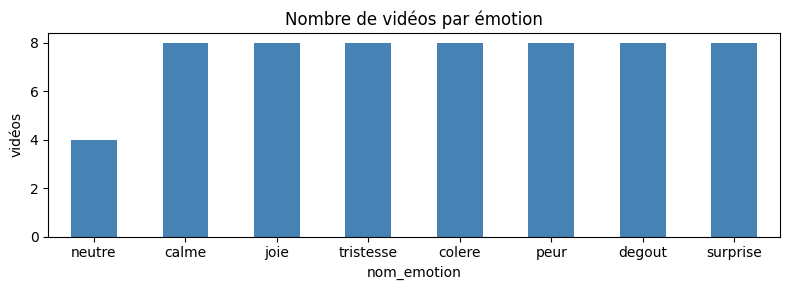

In [20]:
MODALITE = 2 if (df_tout['modalite'] == 2).any() else 1
df = df_tout[(df_tout['modalite'] == MODALITE) & (df_tout['canal'] == 1)]
df = df.sort_values('file').reset_index(drop=True)

df['label'] = df['emotion'] - 1                     # étiquettes de 0 à 7
df['nom_emotion'] = df['label'].apply(lambda i: EMOTIONS[i])

print('Vidéos utilisées :', len(df))

# Répartition des classes
repartition = df['nom_emotion'].value_counts().reindex(EMOTIONS)
repartition.plot(kind='bar', figsize=(8, 3), color='steelblue', rot=0)
plt.title('Nombre de vidéos par émotion')
plt.ylabel('vidéos')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'repartition_classes.png'), dpi=150)
plt.show()

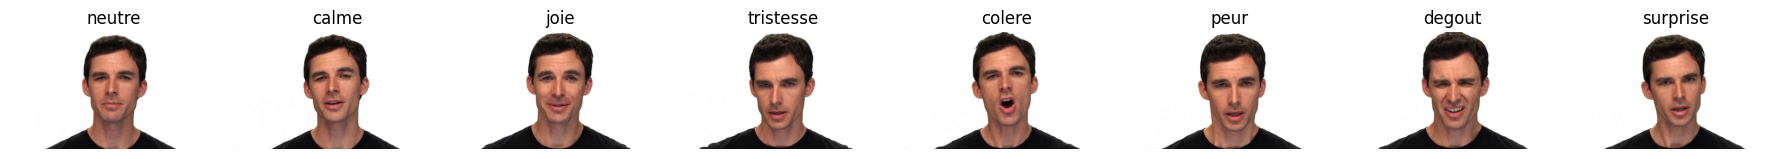

In [21]:
# Affichage d'une frame (au milieu de la vidéo) pour chaque émotion
fig, axes = plt.subplots(1, 8, figsize=(18, 3))
for i, emo in enumerate(EMOTIONS):
    chemin = df[df['label'] == i]['path'].iloc[0]
    fr, _ = lire_frames(chemin)
    axes[i].imshow(cv2.cvtColor(fr[len(fr) // 2], cv2.COLOR_BGR2RGB))
    axes[i].set_title(emo)
    axes[i].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'exemples_emotions.png'), dpi=120)
plt.show()

## 4. Détection et recadrage du visage
L'émotion se lit sur le visage : on recadre donc chaque vidéo autour du visage avec le détecteur **Haar** d'OpenCV.
On détecte le visage sur quelques frames, on prend la boîte médiane (agrandie de 25 %), et on garde ce même recadrage pour toute la vidéo.

Visage détecté : True | forme : (98, 128, 128, 3)


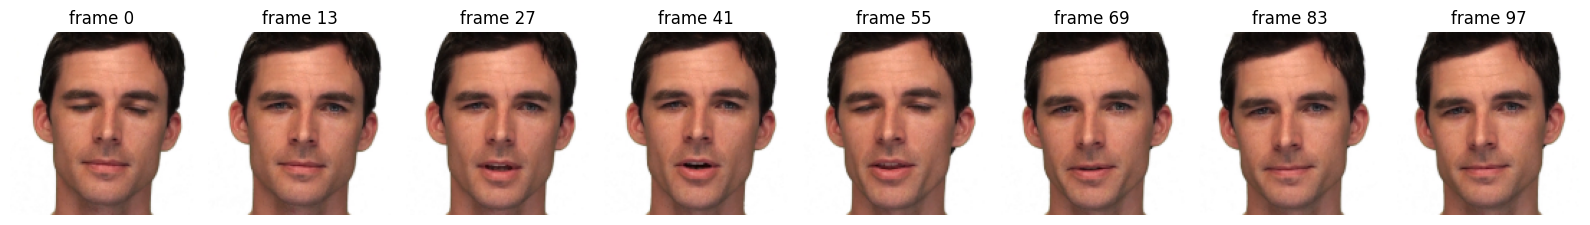

In [22]:
detecteur = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

def boite_visage(frames):
    boites = []
    for f in frames[::8]:                      # une frame sur 8 suffit
        gris = cv2.cvtColor(f, cv2.COLOR_BGR2GRAY)
        det = detecteur.detectMultiScale(gris, 1.1, 5, minSize=(60, 60))
        if len(det) > 0:
            boites.append(max(det, key=lambda b: b[2] * b[3]))   # le plus grand visage
    H, W = frames[0].shape[:2]
    if len(boites) == 0:                       # pas de visage : recadrage au centre
        s = min(H, W)
        return (W - s) // 2, (H - s) // 2, s, False
    x, y, w, h = np.median(np.array(boites), axis=0).astype(int)
    s = min(int(max(w, h) * 1.25), H, W)
    cx, cy = x + w // 2, y + h // 2
    x0 = int(np.clip(cx - s // 2, 0, W - s))
    y0 = int(np.clip(cy - s // 2, 0, H - s))
    return x0, y0, s, True

def recadrer(frames, boite):
    x0, y0, s, _ = boite
    return np.stack([cv2.cvtColor(cv2.resize(f[y0:y0 + s, x0:x0 + s], (IMG, IMG)), cv2.COLOR_BGR2RGB)
                     for f in frames])

# Test sur la première vidéo
boite = boite_visage(frames)
visages = recadrer(frames, boite)
print('Visage détecté :', boite[3], '| forme :', visages.shape)

fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for a, k in zip(axes, np.linspace(0, len(visages) - 1, 8).astype(int)):
    a.imshow(visages[k]); a.set_title(f'frame {k}'); a.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'visages.png'), dpi=120)
plt.show()

## 5. Sélection des frames (contre la redondance)
À environ 30 images/s, deux frames successives sont presque identiques. On compare deux méthodes :

1. **Pas fixe (référence)** : T frames réparties uniformément, sans regarder le contenu (comme l'article).
2. **Méthode proposée, par différence** : on garde la frame *t* seulement si elle est assez différente de la **dernière frame gardée** :

$$d_t = \frac{1}{N}\sum_{p} |f_t(p) - f_{\text{dernière gardée}}(p)| > s$$

Le seuil *s* est la **médiane** des différences entre frames consécutives de la vidéo (seuil adaptatif).
Ensuite on prend T = 16 frames régulièrement espacées parmi les frames gardées.

68 frames gardées sur 98 (31 % de redondance supprimée)


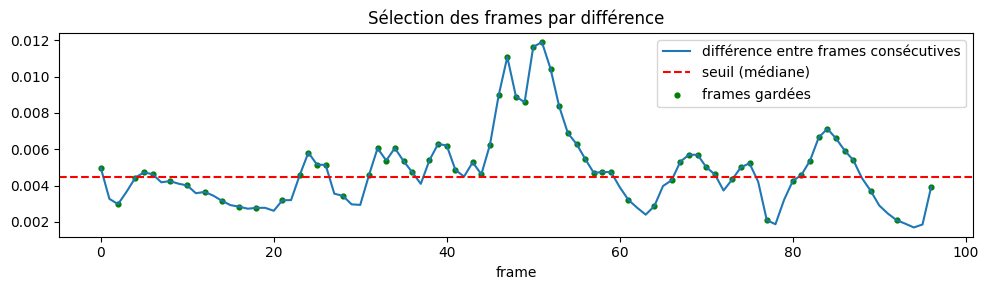

In [23]:
def ramener_a_T(indices, T=T):
    # choisit T indices régulièrement espacés (avec répétition s'il y en a moins de T)
    indices = np.asarray(indices)
    pos = np.round(np.linspace(0, len(indices) - 1, T)).astype(int)
    return indices[pos]

def selection_difference(petites):
    # petites : frames en niveaux de gris 64x64
    g = petites.astype('float32') / 255.
    diff_consecutives = np.abs(np.diff(g, axis=0)).mean(axis=(1, 2))
    seuil = np.median(diff_consecutives)
    gardees = [0]
    for t in range(1, len(g)):
        if np.abs(g[t] - g[gardees[-1]]).mean() > seuil:
            gardees.append(t)
    return np.array(gardees), diff_consecutives, seuil

def en_petit(visages):
    return np.stack([cv2.resize(cv2.cvtColor(v, cv2.COLOR_RGB2GRAY), (64, 64)) for v in visages])

# Test sur la première vidéo
gardees, diffs, seuil = selection_difference(en_petit(visages))
print(f'{len(gardees)} frames gardées sur {len(visages)} ({100 * (1 - len(gardees) / len(visages)):.0f} % de redondance supprimée)')

plt.figure(figsize=(10, 3))
plt.plot(diffs, label='différence entre frames consécutives')
plt.axhline(seuil, color='r', ls='--', label='seuil (médiane)')
plt.scatter(gardees[1:] - 1, diffs[gardees[1:] - 1], color='g', s=12, label='frames gardées')
plt.xlabel('frame'); plt.legend(); plt.title('Sélection des frames par différence')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'selection_frames.png'), dpi=150)
plt.show()

## 6. Extraction des caractéristiques

### 6.1 CNN : VGG16 pré-entraîné (transfer learning)
* VGG16 entraîné sur ImageNet, **sans la partie classification** (`include_top=False`).
* `pooling='avg'` : GlobalAveragePooling, qui transforme la sortie 4×4×512 en **un vecteur de 512 valeurs** (au lieu de 8192 avec Flatten).
* Les poids sont **gelés** : on utilise VGG16 seulement comme extracteur.

In [24]:
cnn = VGG16(weights='imagenet', include_top=False, pooling='avg', input_shape=(IMG, IMG, 3))
cnn.trainable = False

print('Sortie du CNN :', cnn.output_shape)
print('Nombre de paramètres (gelés) :', cnn.count_params())

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Sortie du CNN : (None, 512)
Nombre de paramètres (gelés) : 14714688


### 6.2 Moments couleur (deuxième tâche)
Pour chaque canal R, G, B du visage : la **moyenne** μ et l'**écart-type** σ → **6 valeurs** par frame.

In [25]:
def moments_couleur(visages):
    # visages : (n, 128, 128, 3) -> (n, 6) = [moy_R, moy_G, moy_B, std_R, std_G, std_B]
    x = visages.reshape(len(visages), -1, 3).astype('float32') / 255.
    return np.concatenate([x.mean(axis=1), x.std(axis=1)], axis=1)

print('Moments couleur de la première frame :', moments_couleur(visages[:1]).round(3))

Moments couleur de la première frame : [[0.688 0.554 0.513 0.297 0.331 0.348]]


### 6.3 Extraction pour toutes les vidéos
Les caractéristiques sont calculées pour **toutes** les frames, puis sauvegardées dans Drive (pour ne pas refaire le calcul).
La sélection des frames choisit ensuite les indices à utiliser.

In [26]:
FICHIER_CACHE = os.path.join(OUT_DIR, 'features_cache.pkl')

if os.path.exists(FICHIER_CACHE):
    DATA = pickle.load(open(FICHIER_CACHE, 'rb'))
    print('Caractéristiques chargées depuis le cache.')
else:
    DATA = {}
    debut = time.time()
    for i, ligne in df.iterrows():
        frames, fps = lire_frames(ligne['path'])
        boite = boite_visage(frames)
        visages = recadrer(frames, boite)

        vgg = cnn.predict(preprocess_input(visages.astype('float32')), batch_size=64, verbose=0)
        DATA[ligne['file']] = {
            'vgg': vgg.astype('float32'),          # (n_frames, 512)
            'col': moments_couleur(visages),        # (n_frames, 6)
            'petites': en_petit(visages),           # pour la sélection des frames
            'visage': boite[3],
        }
        print(f"{i + 1:2d}/{len(df)}  {ligne['file']}  {len(frames)} frames  ({time.time() - debut:.0f} s)")
    pickle.dump(DATA, open(FICHIER_CACHE, 'wb'))

print('Visage détecté dans', sum(d['visage'] for d in DATA.values()), 'vidéos sur', len(DATA))

 1/60  02-01-01-01-01-01-01.mp4  98 frames  (28 s)
 2/60  02-01-01-01-01-02-01.mp4  99 frames  (39 s)
 3/60  02-01-01-01-02-01-01.mp4  98 frames  (41 s)
 4/60  02-01-01-01-02-02-01.mp4  94 frames  (50 s)
 5/60  02-01-02-01-01-01-01.mp4  105 frames  (62 s)
 6/60  02-01-02-01-01-02-01.mp4  107 frames  (74 s)
 7/60  02-01-02-01-02-01-01.mp4  104 frames  (86 s)
 8/60  02-01-02-01-02-02-01.mp4  103 frames  (97 s)
 9/60  02-01-02-02-01-01-01.mp4  110 frames  (109 s)
10/60  02-01-02-02-01-02-01.mp4  119 frames  (122 s)
11/60  02-01-02-02-02-01-01.mp4  125 frames  (137 s)
12/60  02-01-02-02-02-02-01.mp4  119 frames  (139 s)
13/60  02-01-03-01-01-01-01.mp4  103 frames  (141 s)
14/60  02-01-03-01-01-02-01.mp4  103 frames  (142 s)
15/60  02-01-03-01-02-01-01.mp4  105 frames  (144 s)
16/60  02-01-03-01-02-02-01.mp4  110 frames  (145 s)
17/60  02-01-03-02-01-01-01.mp4  109 frames  (157 s)
18/60  02-01-03-02-01-02-01.mp4  108 frames  (179 s)
19/60  02-01-03-02-02-01-01.mp4  117 frames  (193 s)
20/60

In [27]:
# Sélection des frames pour toutes les vidéos (les deux méthodes)
stats = []
for f, d in DATA.items():
    n = len(d['vgg'])
    gardees, _, _ = selection_difference(d['petites'])
    d['idx'] = {'uniforme': ramener_a_T(np.arange(n)),
                'difference': ramener_a_T(gardees)}
    stats.append({'file': f, 'n_frames': n, 'n_gardees': len(gardees)})

stats = pd.DataFrame(stats)
stats['redondance_%'] = 100 * (1 - stats['n_gardees'] / stats['n_frames'])
print(stats[['n_frames', 'n_gardees', 'redondance_%']].describe().round(1))

       n_frames  n_gardees  redondance_%
count      60.0       60.0          60.0
mean      111.4       77.4          30.6
std        10.5        7.8           2.0
min        94.0       63.0          26.6
25%       104.0       72.0          29.1
50%       110.0       76.0          30.8
75%       117.0       82.2          32.0
max       149.0      100.0          34.5


## 7. Préparation des séquences et protocole d'évaluation
* Chaque vidéo devient une séquence de **T = 16 vecteurs**.
* Trois jeux de caractéristiques : **couleur** (6), **vgg** (512), **vgg+couleur** (518).
* Un seul acteur → séparation **par vidéo** (aucune frame d'une vidéo de test ne sert à l'apprentissage).
* **Validation croisée stratifiée à 5 plis** ; dans chaque pli, 8 vidéos d'apprentissage servent de validation (EarlyStopping).
* Normalisation `StandardScaler` apprise sur l'apprentissage seulement.

In [28]:
y = df['label'].values
FICHIERS = df['file'].values

def construire_X(methode, features):
    X = []
    for f in FICHIERS:
        d = DATA[f]
        idx = d['idx'][methode]
        if features == 'couleur':
            v = d['col'][idx]
        elif features == 'vgg':
            v = d['vgg'][idx]
        else:                                        # 'vgg+couleur'
            v = np.concatenate([d['vgg'][idx], d['col'][idx]], axis=1)
        X.append(v)
    return np.stack(X).astype('float32')

def normaliser(X_train, *autres):
    D = X_train.shape[-1]
    sc = StandardScaler().fit(X_train.reshape(-1, D))
    return [sc.transform(a.reshape(-1, D)).reshape(a.shape).astype('float32') for a in (X_train,) + autres]

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
PLIS = list(skf.split(np.zeros(len(y)), y))
for k, (tr, te) in enumerate(PLIS):
    print(f'Pli {k + 1} : {len(tr)} vidéos apprentissage, {len(te)} vidéos test')

print('Forme de X (vgg+couleur) :', construire_X('difference', 'vgg+couleur').shape)

Pli 1 : 48 vidéos apprentissage, 12 vidéos test
Pli 2 : 48 vidéos apprentissage, 12 vidéos test
Pli 3 : 48 vidéos apprentissage, 12 vidéos test
Pli 4 : 48 vidéos apprentissage, 12 vidéos test
Pli 5 : 48 vidéos apprentissage, 12 vidéos test
Forme de X (vgg+couleur) : (60, 16, 518)


In [29]:
def metriques(y_vrai, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(y_vrai, y_pred, average='macro', zero_division=0)
    return {'accuracy': accuracy_score(y_vrai, y_pred), 'precision': p, 'rappel': r, 'f1': f1}

def arret_anticipe():
    return keras.callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)

def tracer_confusion(cm, titre, ax):
    sns.heatmap(np.array(cm), annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=EMOTIONS, yticklabels=EMOTIONS, ax=ax)
    ax.set_title(titre); ax.set_xlabel('prédit'); ax.set_ylabel('vrai')

## 8. Métriques du CNN extracteur (sans modèle temporel)
VGG16 gelé ne classe rien seul : on ajoute une petite tête **Dense(64, ReLU) → Dropout(0.3) → Dense(8, softmax)** entraînée sur les vecteurs de chaque frame.
* **Niveau frame** : chaque frame est classée seule.
* **Niveau vidéo** : vote majoritaire des 16 frames (comme l'article de référence, l'ordre est ignoré).

In [30]:
def tete_frame(D):
    m = keras.Sequential([keras.Input((D,)),
                          layers.Dense(64, activation='relu'),
                          layers.Dropout(0.3),
                          layers.Dense(8, activation='softmax')])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

RES_CNN = {}
for features in ['vgg', 'vgg+couleur']:
    X = construire_X('difference', features)
    D = X.shape[-1]
    vrai_frame, pred_frame = [], []
    pred_video = np.zeros(len(y), dtype=int)
    acc_f, acc_v = [], []

    for k, (tr, te) in enumerate(PLIS):
        fixer_graine(SEED + k)
        tr2, va = train_test_split(tr, test_size=8, stratify=y[tr], random_state=SEED)
        Xtr, Xva, Xte = normaliser(X[tr2], X[va], X[te])

        m = tete_frame(D)
        m.fit(Xtr.reshape(-1, D), np.repeat(y[tr2], T),
              validation_data=(Xva.reshape(-1, D), np.repeat(y[va], T)),
              epochs=200, batch_size=32, callbacks=[arret_anticipe()], verbose=0)

        p = m.predict(Xte.reshape(-1, D), verbose=0).argmax(axis=1).reshape(len(te), T)
        vote = np.array([np.bincount(ligne, minlength=8).argmax() for ligne in p])

        vrai_frame += list(np.repeat(y[te], T)); pred_frame += list(p.ravel())
        pred_video[te] = vote
        acc_f.append(accuracy_score(np.repeat(y[te], T), p.ravel()))
        acc_v.append(accuracy_score(y[te], vote))

    RES_CNN[features] = {'frame': metriques(vrai_frame, pred_frame), 'video': metriques(y, pred_video),
                         'acc_frame_std': float(np.std(acc_f)), 'acc_video_std': float(np.std(acc_v)),
                         'cm_frame': confusion_matrix(vrai_frame, pred_frame, labels=range(8)).tolist(),
                         'cm_video': confusion_matrix(y, pred_video, labels=range(8)).tolist()}

tableau_cnn = pd.DataFrame({f'{f} / {niv}': RES_CNN[f][niv] for f in RES_CNN for niv in ['frame', 'video']}).T.round(3)
tableau_cnn

,accuracy,precision,rappel,f1
vgg / frame,0.582,0.545,0.553,0.545
vgg / video,0.700,0.687,0.672,0.666
vgg+couleur / frame,0.592,0.551,0.560,0.552
vgg+couleur / video,0.683,0.636,0.641,0.627


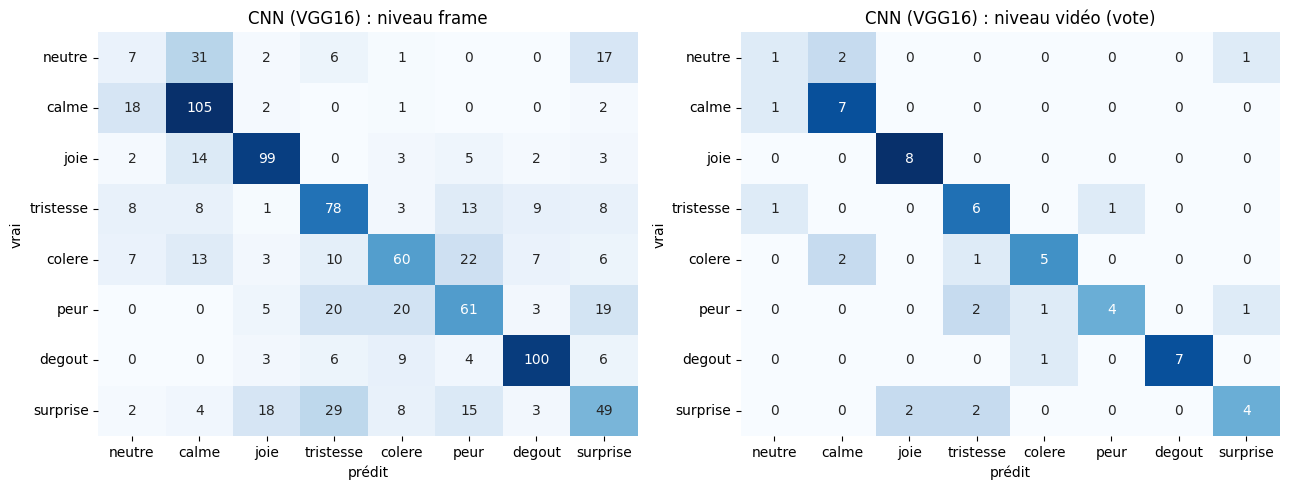

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
tracer_confusion(RES_CNN['vgg']['cm_frame'], 'CNN (VGG16) : niveau frame', axes[0])
tracer_confusion(RES_CNN['vgg']['cm_video'], 'CNN (VGG16) : niveau vidéo (vote)', axes[1])
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'cm_cnn.png'), dpi=150)
plt.show()

## 9. Modèles séquentiels : RNN, LSTM, GRU, Transformer
Les 4 modèles reçoivent la même séquence (16 × D) et ont la même sortie **Dense(8, softmax)**.
* 64 unités, Dropout 0.3, optimiseur Adam (lr = 0.001), perte `sparse_categorical_crossentropy`
* jusqu'à 200 époques, lots de 8 vidéos, EarlyStopping (patience 20)

In [32]:
class EmbeddingPosition(layers.Layer):
    # ajoute à chaque frame un vecteur appris qui code sa position dans la séquence
    def __init__(self, longueur, dim, **kwargs):
        super().__init__(**kwargs)
        self.longueur = longueur
        self.emb = layers.Embedding(longueur, dim)
    def call(self, x):
        return x + self.emb(tf.range(self.longueur))

def creer_modele(type_modele, D, unites=64, dropout=0.3):
    entree = keras.Input(shape=(T, D))

    if type_modele == 'RNN':
        x = layers.SimpleRNN(unites)(entree)
    elif type_modele == 'LSTM':
        x = layers.LSTM(unites)(entree)
    elif type_modele == 'GRU':
        x = layers.GRU(unites)(entree)
    else:  # Transformer (un bloc encodeur)
        x = layers.Dense(unites)(entree)
        x = EmbeddingPosition(T, unites)(x)
        att = layers.MultiHeadAttention(num_heads=4, key_dim=unites // 4, dropout=0.1)(x, x)
        x = layers.LayerNormalization(epsilon=1e-6)(layers.Add()([x, att]))
        ff = layers.Dense(unites * 2, activation='relu')(x)
        ff = layers.Dense(unites)(ff)
        x = layers.LayerNormalization(epsilon=1e-6)(layers.Add()([x, ff]))
        x = layers.GlobalAveragePooling1D()(x)

    x = layers.Dropout(dropout)(x)
    sortie = layers.Dense(8, activation='softmax')(x)
    modele = keras.Model(entree, sortie, name=type_modele)
    modele.compile(optimizer=keras.optimizers.Adam(1e-3),
                   loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return modele

MODELES = ['RNN', 'LSTM', 'GRU', 'Transformer']
PARAMS = {m: int(creer_modele(m, 518).count_params()) for m in MODELES}
print('Nombre de paramètres (D = 518) :', PARAMS)

Nombre de paramètres (D = 518) : {'RNN': 37832, 'LSTM': 149768, 'GRU': 112648, 'Transformer': 68232}


In [33]:
creer_modele('Transformer', 518).summary()

Model: "Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_15      │ (None, 16, 518)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_27 (Dense)    │ (None, 16, 64)    │     33,216 │ input_layer_15[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_position… │ (None, 16, 64)    │      1,024 │ dense_27[0][0]    │
│ (EmbeddingPosition) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 16, 64)    │     16,640 │ embedding_positi… │
│ (MultiHeadAttentio… │                   │            │ embedding_positi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 16, 64)    │          0 │ embedding_positi… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 16, 64)    │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_28 (Dense)    │ (None, 16, 128)   │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_29 (Dense)    │ (None, 16, 64)    │      8,256 │ dense_28[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 16, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dense_29[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 16, 64)    │        128 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_16          │ (None, 64)        │          0 │ global_average_p… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_30 (Dense)    │ (None, 8)         │        520 │ dropout_16[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 68,232 (266.53 KB)

 Trainable params: 68,232 (266.53 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
def validation_croisee(type_modele, methode, features):
    X = construire_X(methode, features)
    D = X.shape[-1]
    pred = np.zeros(len(y), dtype=int)
    accs, historique = [], None
    debut = time.time()

    for k, (tr, te) in enumerate(PLIS):
        fixer_graine(SEED + k)
        keras.backend.clear_session()
        tr2, va = train_test_split(tr, test_size=8, stratify=y[tr], random_state=SEED)
        Xtr, Xva, Xte = normaliser(X[tr2], X[va], X[te])

        m = creer_modele(type_modele, D)
        h = m.fit(Xtr, y[tr2], validation_data=(Xva, y[va]), epochs=200, batch_size=8,
                  callbacks=[arret_anticipe()], verbose=0)
        if k == 0:
            historique = h.history
        pred[te] = m.predict(Xte, verbose=0).argmax(axis=1)
        accs.append(accuracy_score(y[te], pred[te]))

    res = metriques(y, pred)
    res.update({'modele': type_modele, 'selection': methode, 'features': features, 'D': D,
                'acc_std_plis': float(np.std(accs)), 'temps_s': time.time() - debut,
                'cm': confusion_matrix(y, pred, labels=range(8)).tolist(),
                'pred': pred.tolist(), 'hist': historique})
    print(f"{type_modele:12s} {features:12s} {methode:10s} accuracy = {res['accuracy']:.3f} "
          f"(± {np.std(accs):.3f})   F1 = {res['f1']:.3f}   {res['temps_s']:.0f} s")
    return res

FEATURES = ['couleur', 'vgg', 'vgg+couleur']
RESULTATS = []

### 9.1 RNN

In [35]:
for f in FEATURES:
    RESULTATS.append(validation_croisee('RNN', 'difference', f))

RNN          couleur      difference accuracy = 0.383 (± 0.227)   F1 = 0.343   42 s
RNN          vgg          difference accuracy = 0.600 (± 0.097)   F1 = 0.575   70 s
RNN          vgg+couleur  difference accuracy = 0.617 (± 0.085)   F1 = 0.589   66 s


### 9.2 LSTM

In [36]:
for f in FEATURES:
    RESULTATS.append(validation_croisee('LSTM', 'difference', f))

LSTM         couleur      difference accuracy = 0.317 (± 0.133)   F1 = 0.272   35 s
LSTM         vgg          difference accuracy = 0.567 (± 0.162)   F1 = 0.527   35 s
LSTM         vgg+couleur  difference accuracy = 0.583 (± 0.183)   F1 = 0.542   55 s


### 9.3 GRU

In [37]:
for f in FEATURES:
    RESULTATS.append(validation_croisee('GRU', 'difference', f))

GRU          couleur      difference accuracy = 0.350 (± 0.143)   F1 = 0.319   27 s
GRU          vgg          difference accuracy = 0.567 (± 0.111)   F1 = 0.525   38 s
GRU          vgg+couleur  difference accuracy = 0.600 (± 0.082)   F1 = 0.565   37 s


### 9.4 Transformer

In [38]:
for f in FEATURES:
    RESULTATS.append(validation_croisee('Transformer', 'difference', f))

Transformer  couleur      difference accuracy = 0.317 (± 0.153)   F1 = 0.316   71 s
Transformer  vgg          difference accuracy = 0.633 (± 0.194)   F1 = 0.605   62 s
Transformer  vgg+couleur  difference accuracy = 0.633 (± 0.194)   F1 = 0.605   60 s


### 9.5 Effet de la sélection des frames
Mêmes modèles avec les caractéristiques VGG16 + couleur, mais avec la sélection à **pas fixe** (uniforme).

In [39]:
for m in MODELES:
    RESULTATS.append(validation_croisee(m, 'uniforme', 'vgg+couleur'))

RNN          vgg+couleur  uniforme   accuracy = 0.600 (± 0.062)   F1 = 0.550   44 s
LSTM         vgg+couleur  uniforme   accuracy = 0.583 (± 0.118)   F1 = 0.533   41 s
GRU          vgg+couleur  uniforme   accuracy = 0.550 (± 0.100)   F1 = 0.517   33 s
Transformer  vgg+couleur  uniforme   accuracy = 0.600 (± 0.162)   F1 = 0.557   60 s


## 10. Comparaison des résultats

In [40]:
tableau = pd.DataFrame([{k: r[k] for k in ['modele', 'features', 'selection', 'accuracy', 'acc_std_plis',
                                            'precision', 'rappel', 'f1', 'temps_s']} for r in RESULTATS]).round(3)
tableau.to_csv(os.path.join(OUT_DIR, 'resultats_sequentiels.csv'), index=False)
tableau

,modele,features,selection,accuracy,acc_std_plis,precision,rappel,f1,temps_s
0,RNN,couleur,difference,0.383,0.227,0.363,0.359,0.343,41.509
1,RNN,vgg,difference,0.600,0.097,0.582,0.578,0.575,69.714
2,RNN,vgg+couleur,difference,0.617,0.085,0.594,0.594,0.589,66.040
3,LSTM,couleur,difference,0.317,0.133,0.275,0.297,0.272,35.113
4,LSTM,vgg,difference,0.567,0.162,0.535,0.531,0.527,35.337
5,LSTM,vgg+couleur,difference,0.583,0.183,0.558,0.547,0.542,54.960
6,GRU,couleur,difference,0.350,0.143,0.371,0.328,0.319,27.416
7,GRU,vgg,difference,0.567,0.111,0.538,0.531,0.525,38.062
8,GRU,vgg+couleur,difference,0.600,0.082,0.598,0.562,0.565,36.676
9,Transformer,couleur,difference,0.317,0.153,0.358,0.312,0.316,70.749


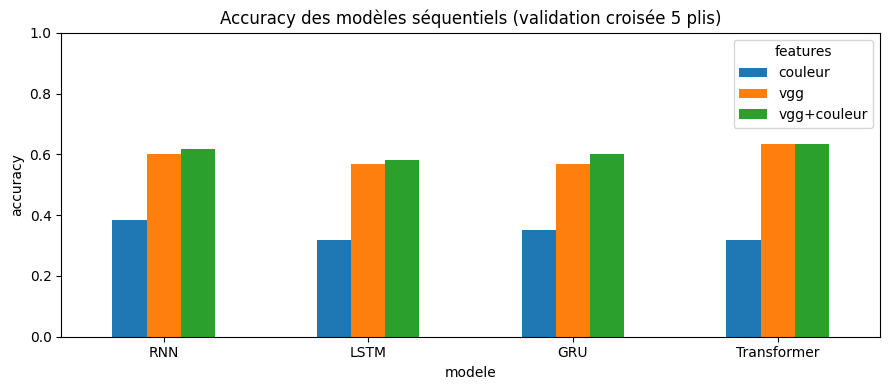

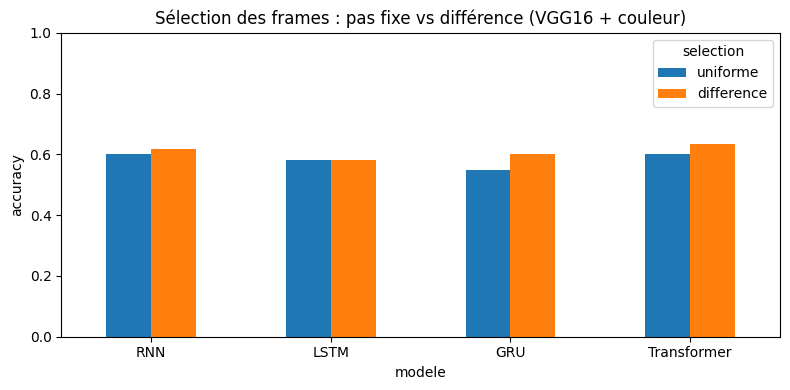

In [41]:
# Accuracy des 4 modèles pour chaque jeu de caractéristiques
t = tableau[tableau['selection'] == 'difference'].pivot(index='modele', columns='features', values='accuracy').reindex(MODELES)
t[FEATURES].plot(kind='bar', figsize=(9, 4), rot=0, ylim=(0, 1))
plt.title('Accuracy des modèles séquentiels (validation croisée 5 plis)')
plt.ylabel('accuracy')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'comparaison_modeles.png'), dpi=150)
plt.show()

# Sélection uniforme vs sélection par différence
s = tableau[tableau['features'] == 'vgg+couleur'].pivot(index='modele', columns='selection', values='accuracy').reindex(MODELES)
s[['uniforme', 'difference']].plot(kind='bar', figsize=(8, 4), rot=0, ylim=(0, 1))
plt.title('Sélection des frames : pas fixe vs différence (VGG16 + couleur)')
plt.ylabel('accuracy')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'comparaison_selection.png'), dpi=150)
plt.show()

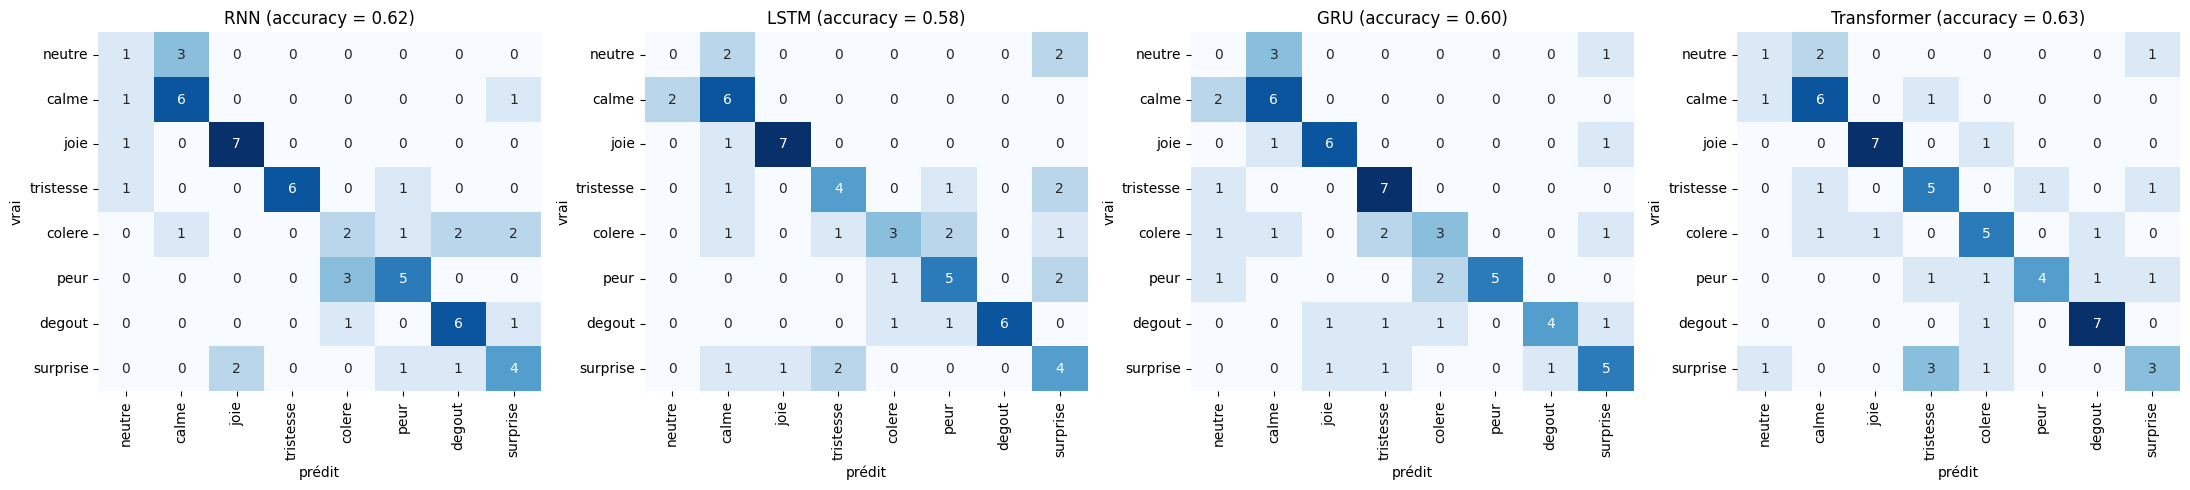

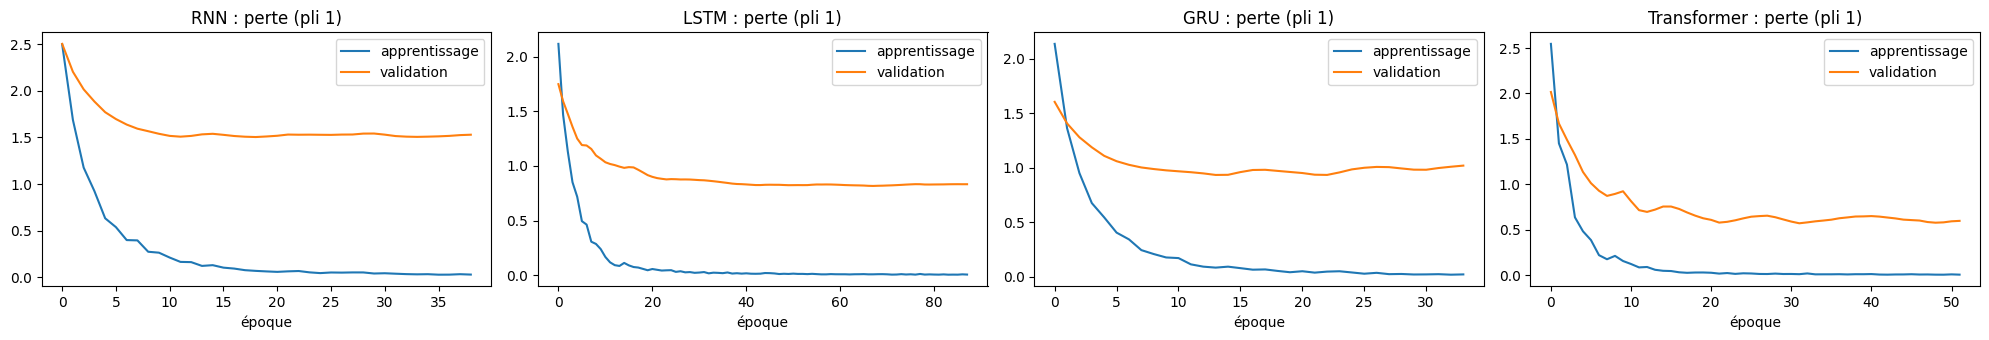

In [42]:
# Matrices de confusion des 4 modèles (VGG16 + couleur, sélection par différence)
choix = [r for r in RESULTATS if r['features'] == 'vgg+couleur' and r['selection'] == 'difference']
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, r in zip(axes, choix):
    tracer_confusion(r['cm'], f"{r['modele']} (accuracy = {r['accuracy']:.2f})", ax)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'cm_sequentiels.png'), dpi=150)
plt.show()

# Courbes d'apprentissage (pli 1)
fig, axes = plt.subplots(1, 4, figsize=(20, 3.5))
for ax, r in zip(axes, choix):
    ax.plot(r['hist']['loss'], label='apprentissage')
    ax.plot(r['hist']['val_loss'], label='validation')
    ax.set_title(f"{r['modele']} : perte (pli 1)"); ax.set_xlabel('époque'); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'courbes_apprentissage.png'), dpi=150)
plt.show()

In [43]:
meilleur = max(RESULTATS, key=lambda r: (r['accuracy'], r['f1']))
print(f"Meilleure configuration : {meilleur['modele']} / {meilleur['features']} / sélection {meilleur['selection']}")
print(classification_report(y, meilleur['pred'], target_names=EMOTIONS, zero_division=0))

Meilleure configuration : Transformer / vgg / sélection difference
              precision    recall  f1-score   support

      neutre       0.50      0.25      0.33         4
       calme       0.60      0.75      0.67         8
        joie       0.88      0.88      0.88         8
   tristesse       0.50      0.62      0.56         8
      colere       0.56      0.62      0.59         8
        peur       0.67      0.50      0.57         8
      degout       0.78      0.88      0.82         8
    surprise       0.50      0.38      0.43         8

    accuracy                           0.63        60
   macro avg       0.62      0.61      0.61        60
weighted avg       0.63      0.63      0.62        60



## 11. Sauvegarde des résultats

In [44]:
resume = {
    'n_videos': int(len(df)), 'modalite': int(MODALITE),
    'repartition': {k: int(v) for k, v in repartition.items()},
    'T': T, 'IMG': IMG, 'n_folds': N_FOLDS,
    'params_D518': PARAMS, 'vgg_params': int(cnn.count_params()),
    'selection': {'frames_moy': float(stats['n_frames'].mean()),
                  'gardees_moy': float(stats['n_gardees'].mean()),
                  'redondance_moy_pct': float(stats['redondance_%'].mean()),
                  'redondance_min_pct': float(stats['redondance_%'].min()),
                  'redondance_max_pct': float(stats['redondance_%'].max())},
    'visage_detecte': int(sum(d['visage'] for d in DATA.values())),
    'cnn': RES_CNN,
    'sequentiels': [{k: v for k, v in r.items() if k not in ('pred', 'hist')} for r in RESULTATS],
    'meilleur': {'modele': meilleur['modele'], 'features': meilleur['features'], 'selection': meilleur['selection'],
                 'rapport': classification_report(y, meilleur['pred'], target_names=EMOTIONS,
                                                  zero_division=0, output_dict=True)},
}
json.dump(resume, open(os.path.join(OUT_DIR, 'resultats.json'), 'w'), indent=1, default=float)
print('Résultats sauvegardés dans', OUT_DIR)
print(os.listdir(OUT_DIR))

Résultats sauvegardés dans /content/drive/MyDrive/RAVDESS_Projet_Resultats
['repartition_classes.png', 'exemples_emotions.png', 'visages.png', 'selection_frames.png', 'features_cache.pkl', 'cm_cnn.png', 'resultats_sequentiels.csv', 'comparaison_modeles.png', 'comparaison_selection.png', 'cm_sequentiels.png', 'courbes_apprentissage.png', 'resultats.json']


## Conclusion
*(Voir le rapport PDF pour l'analyse détaillée des résultats.)*